# Rate against accuracy: every encoder on one pair of axes

**Question.** What does task-oriented ("semantic") communication buy a WISP camera over sending a picture, and how much of that survives when the server has to learn the room by itself?

Every point below is scored on the same ground truth, PIROPO `test1`–`test3`, with nothing tuned on those frames. The metric is **balanced accuracy** (mean of person recall and empty recall) of a yes/no answer, because the adaptive loop gives answers rather than scores; AUCs are in the tables where a score exists. Three kinds of receiver:

* **Generic** (orange): the COCO person detector on whatever the tag sent, decoded back to an image. No knowledge of the room; threshold tuned on `training` + `training_seats`. This is "compress the picture, then infer".
* **Room-trained** (blue): a small CNN trained on ~3,000 *true* labels of this room, on exactly the payload the tag sends (`thumbnail_sweep.py`). The favourable case: an upper bound on what a decoder that knows the room can do at each size.
* **Adaptive, no labels** (aqua): the online loop of `online_adaptation.py` / `tiered_checks.py`, first pass, detector as teacher. Bytes per query include every check the server makes.

Encoders: block-mean **thumbnails** (any size and bit depth), **JPEG** of a thumbnail (`semwisp.tag.JpegTag`, header not counted), and the 96-bit **interval code** (one EPC).

This notebook only reads cached results (`experiments/rate_accuracy.py` holds the loaders).

**Findings in brief** (first run, 2026-11-11).
1. **Knowing the room is worth about 600× in bytes.** A generic detector needs about 7 KB of JPEG (balanced accuracy 0.90) or the full 19.2 KB frame (0.92) to answer, and is at chance below about 1 KB. A decoder trained on this room gets 0.91 from **12 bytes (one EPC)** and 0.95 from 192 bytes. This is the semantic-communication result: the gain comes from what the receiver knows about the task and the scene, not from a better codec.
2. **JPEG is not the answer at small sizes.** With a room-trained decoder, JPEG ties plain thumbnails from about 80 bytes up and is worse below (AUC 0.80 at 17.5 bytes against 0.95 for the 12-byte thumbnail); it cannot reach one EPC at all. With the generic detector it helps (0.90 at 7 KB against 0.78 for a 4.8 KB thumbnail), but only in the kilobyte range.
3. **Under EPC loss, small payloads win.** With 20% of EPCs lost and no retransmission, the one-EPC code keeps AUC 0.90 while the 70-EPC thumbnail drops to 0.88 and JPEG collapses to chance (0.49 for 160×120): one lost EPC corrupts the rest of a JPEG scan.
4. **Without labels, the adaptive loop sits in between**: balanced accuracy 0.82–0.87 on the same test frames at 2.7–7.5 KB per query. The best is the batch learner with tiered checks (0.870 at 2.7 KB, against 0.825 at 5.3 KB with full-frame checks). Compared with the supervised one-EPC code it pays about 200× in bytes and 0.04 in accuracy: that gap is the cost of learning the room online from a noisy teacher, and closing it is the open problem.
5. **Learning once and never adapting** gives 0.72 at 12 bytes: the room changes between sequences, so a code fitted to the first minutes does not hold.

In [6]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve())); sys.path.insert(0, str(Path('.').resolve()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rate_accuracy as R

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.edgecolor': '#b5b4ae', 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'lines.linewidth': 2})
from matplotlib.ticker import FuncFormatter, NullFormatter
def logx(ax):
    ax.set_xscale('log')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}')); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.precision', 3)
sup, gen, ada, static = R.supervised(), R.generic(), R.adaptive('detector'), R.static_code()
ada_or = R.adaptive('oracle')

## 0. What the receivers actually get

The charts below compare receivers by bytes and accuracy. This section shows what those bytes are: the three kinds of receiver as a diagram, then three real test frames as each encoder delivers them to the server, with the answer each receiver gave.

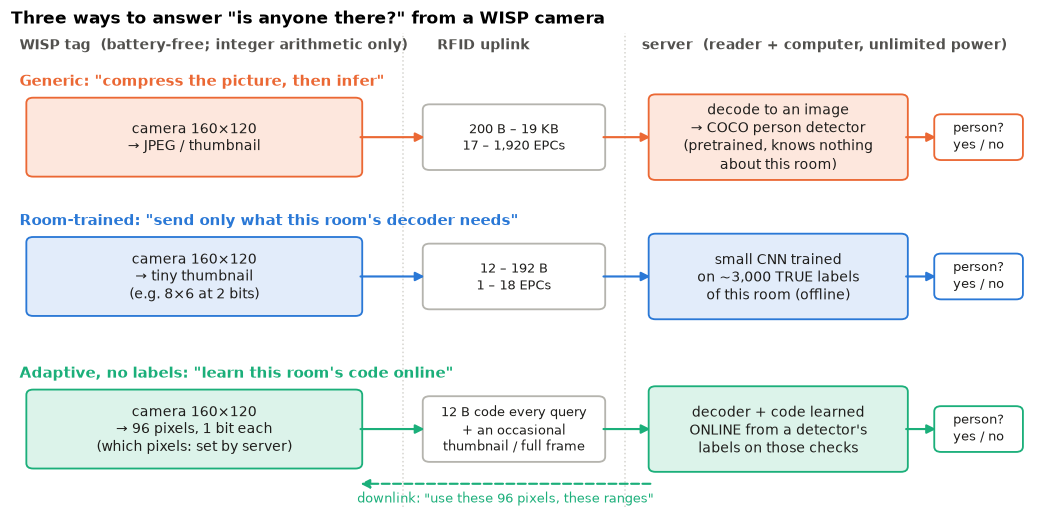

In [7]:
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, text, fc='white', ec='#52514e', lw=1.2, fs=9, bold=False, tc='#1f1e1c'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec=ec, lw=lw))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, color=tc,
            fontweight='bold' if bold else 'normal', linespacing=1.3)

def arrow(ax, x0, y0, x1, y1, text=None, color='#52514e', fs=8.5, dy=0.12, lw=1.4, ls='-'):
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=lw, ls=ls,
                                                        shrinkA=0, shrinkB=0, mutation_scale=12))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + dy, text, ha='center', va='bottom', fontsize=fs, color=color)

def diagram_receivers():
    fig, ax = plt.subplots(figsize=(12, 5.6))
    ax.set_xlim(0, 12); ax.set_ylim(0, 7.15); ax.axis('off')
    TINT = dict(o='#fde7dd', b='#e2ecfa', a='#dcf3ea', g='#efeeea')
    ax.text(0.1, 6.9, 'WISP tag  (battery-free; integer arithmetic only)', fontsize=9, color='#52514e', fontweight='bold')
    ax.text(5.0, 6.9, 'RFID uplink', fontsize=9, color='#52514e', fontweight='bold')
    ax.text(7.4, 6.9, 'server  (reader + computer, unlimited power)', fontsize=9, color='#52514e', fontweight='bold')
    ax.axvline(4.6, color='#d6d5d0', lw=1, ls=':'); ax.axvline(7.2, color='#d6d5d0', lw=1, ls=':')
    rows = [(5.0, ORANGE, 'o', 'Generic: "compress the picture, then infer"',
             'camera 160×120\n→ JPEG / thumbnail', '200 B – 19 KB\n17 – 1,920 EPCs',
             'decode to an image\n→ COCO person detector\n(pretrained, knows nothing\nabout this room)'),
            (2.9, BLUE, 'b', 'Room-trained: "send only what this room\'s decoder needs"',
             'camera 160×120\n→ tiny thumbnail\n(e.g. 8×6 at 2 bits)', '12 – 192 B\n1 – 18 EPCs',
             'small CNN trained\non ~3,000 TRUE labels\nof this room (offline)'),
            (0.6, AQUA, 'a', 'Adaptive, no labels: "learn this room\'s code online"',
             'camera 160×120\n→ 96 pixels, 1 bit each\n(which pixels: set by server)', '12 B code every query\n+ an occasional\nthumbnail / full frame',
             'decoder + code learned\nONLINE from a detector\'s\nlabels on those checks')]
    for y, c, t, title, tag, link, srv in rows:
        ax.text(0.1, y + 1.35, title, fontsize=10, color=c, fontweight='bold')
        box(ax, 0.2, y, 3.9, 1.15, tag, fc=TINT[t], ec=c)
        box(ax, 4.85, y + 0.1, 2.1, 0.95, link, fc='white', ec='#b5b4ae', fs=8.5)
        box(ax, 7.5, y - 0.05, 3.0, 1.25, srv, fc=TINT[t], ec=c)
        arrow(ax, 4.1, y + 0.575, 4.85, y + 0.575, color=c)
        arrow(ax, 6.95, y + 0.575, 7.5, y + 0.575, color=c)
        box(ax, 10.85, y + 0.25, 1.0, 0.65, 'person?\nyes / no', fc='white', ec=c, fs=8.5)
        arrow(ax, 10.5, y + 0.575, 10.85, y + 0.575, color=c)
    # the downlink of the adaptive loop
    arrow(ax, 7.5, 0.35, 4.1, 0.35, 'downlink: "use these 96 pixels, these ranges"', color=AQUA, dy=-0.33, ls='--')
    ax.set_title('Three ways to answer "is anyone there?" from a WISP camera', loc='left')
    return fig

diagram_receivers(); plt.show()


**The three receivers.** All three get their input from the same WISP camera; they differ in what the tag sends and in what the server knows. The generic receiver knows nothing about the room, so the tag must send a picture good enough for a general-purpose detector. The room-trained receiver knows the room (from true labels, offline), so the tag can send almost nothing. The adaptive loop is the deployable version of the second: the server learns the room by itself, from a detector's labels on the occasional full frame it fetches, and tells the tag which 96 pixels to watch.

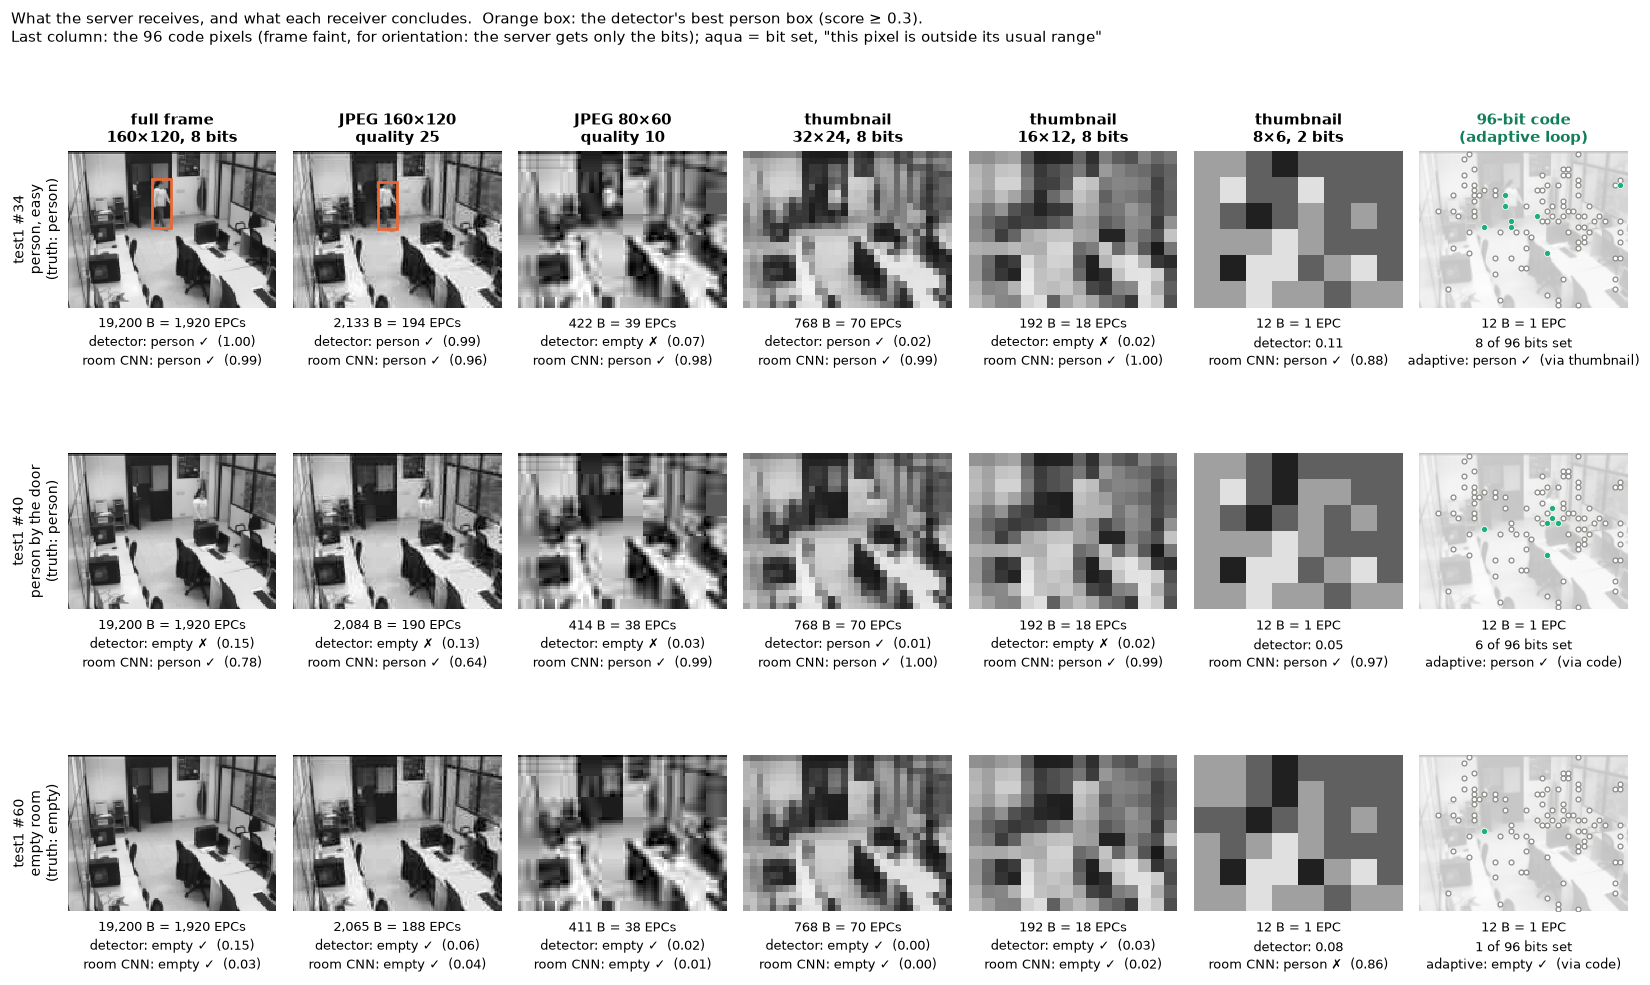

In [8]:
import json, torch, torchvision.models.detection as D
from semwisp.frames import load_frames
from semwisp.link import Link
from semwisp.tag.jpeg import JpegTag
from semwisp.tag.thumbnail import block_mean
from semwisp.tag.interval import IntervalCode, cell_sums, code_bits
import rate_accuracy as R
torch.set_num_threads(4)
DET = D.fasterrcnn_mobilenet_v3_large_320_fpn(weights=D.FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT,
                                              box_score_thresh=0.01).eval()

def detect(img):
    """(person score, best person box in 160x120 coordinates) of the COCO detector on a uint8 image of any size."""
    x = torch.from_numpy(np.repeat(img[..., None], 3, -1)).permute(2, 0, 1).float() / 255
    with torch.no_grad():
        o = DET([x])[0]
    keep = o['labels'] == 1
    if not keep.any():
        return 0.0, None
    j = int(o['scores'][keep].argmax())
    sx, sy = 160 / img.shape[1], 120 / img.shape[0]
    return float(o['scores'][keep][j]), o['boxes'][keep][j].numpy() * [sx, sy, sx, sy]

def coarse(x, w, h, bits):
    """What the server rebuilds from a w x h thumbnail with `bits` bits per pixel."""
    q = block_mean(x, w, h) >> (8 - bits)
    return ((q.astype(float) + 0.5) * (256 >> bits)).astype(np.uint8)

def jpeg(w, h, q):
    t = JpegTag(w, h, q)
    return lambda x: (t.decode(t.encode(x)), len(t.encode(x)))

# name, encoder (frame -> (image the server rebuilds, payload bytes)), thumbnail_sweep run, detector condition
ENC = [('full frame\n160×120, 8 bits', lambda x: (x, 19200), '160x120_b8_mean', '160x120'),
       ('JPEG 160×120\nquality 25', jpeg(160, 120, 25), '160x120_q25_jpeg', 'jpeg160x120q25'),
       ('JPEG 80×60\nquality 10', jpeg(80, 60, 10), '80x60_q10_jpeg', 'jpeg80x60q10'),
       ('thumbnail\n32×24, 8 bits', lambda x: (coarse(x, 32, 24, 8), 768), '32x24_b8_mean', '32x24'),
       ('thumbnail\n16×12, 8 bits', lambda x: (coarse(x, 16, 12, 8), 192), '16x12_b8_mean', '16x12'),
       ('thumbnail\n8×6, 2 bits', lambda x: (coarse(x, 8, 6, 2), 12), '8x6_b2_mean', None)]
EXAMPLES = [('test1', 34, 'person, easy'), ('test1', 40, 'person by the door'), ('test1', 60, 'empty room')]
frames = load_frames(['test1', 'test2', 'test3'])
gen_thr = R.generic().set_index('name')
room_cnn = {e[2]: R.load_npz(Path('../results/thumbnail_sweep') / f'{e[2]}.npz')[1] for e in ENC}
# the adaptive loop (96 pixels, detector teacher, tiered checks), first pass: its run and every code it deployed
RUN = 'piropo_detector_online_pixels_tiered_b200'
_, ada_run = R.load_npz(Path('../results/tiered_checks') / f'{RUN}.npz')
snap = np.load(Path('../results/tiered_checks/snapshots') / f'{RUN}.npz')

def code_at(q):
    """The code on the tag at query q (the last one sent on or before it)."""
    j = np.searchsorted(snap['query'], q, side='right') - 1
    return IntervalCode(np.arange(96), snap['lo'][j], snap['hi'][j], snap['rects'][j]), snap['coef'][j], snap['intercept'][j]

def epcs(n):
    return Link().n_epcs(n)[0]

YES = lambda v: 'person' if v else 'empty'
TICK = lambda ok: '✓' if ok else '✗'

def tidy(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

fig, axs = plt.subplots(len(EXAMPLES), len(ENC) + 1, figsize=(15, 2.9 * len(EXAMPLES) + 0.7))
for r, (seq, i, what) in enumerate(EXAMPLES):
    x, y = frames[seq]['X'][i], int(frames[seq]['label'][i])
    for c, (name, enc, sweep, cond) in enumerate(ENC):
        ax = axs[r, c]; tidy(ax)
        img, nb = enc(x)
        ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest', extent=(0, 160, 120, 0))
        p, b = detect(img)
        if b is not None and p >= 0.3:
            ax.add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec=ORANGE, lw=1.8))
        thr = gen_thr.threshold.get(cond) if cond else None
        gtxt = (f'detector: {p:.2f}' if thr is None else
                f'detector: {YES(p >= thr)} {TICK((p >= thr) == y)}  ({p:.2f})')
        d = room_cnn[sweep]; row = d[(d.seq == seq) & (d.idx == i)]
        q = 1 / (1 + np.exp(-float(row.score.iloc[0])))
        ax.set_xlabel(f'{nb:,} B = {epcs(nb):,} EPC{"s" if epcs(nb) > 1 else ""}\n{gtxt}\n'
                      f'room CNN: {YES(q >= 0.5)} {TICK((q >= 0.5) == y)}  ({q:.2f})', fontsize=8.5, linespacing=1.45)
        if r == 0:
            ax.set_title(name, fontsize=9.5)
        if c == 0:
            ax.set_ylabel(f'{seq} #{i}\n{what}\n(truth: {YES(y)})', fontsize=9)
    # the adaptive loop's 96-bit code for the same frame
    ax = axs[r, -1]; tidy(ax)
    qi = int(np.flatnonzero((ada_run['pass'] == 1) & (ada_run.seq == seq) & (ada_run.idx == i // 2))[0])  # run uses every 2nd frame
    code, coef, icpt = code_at(qi)
    bits = code_bits(cell_sums(x, code.table), code)
    logit = float(bits @ coef + icpt)
    px, py = code.rects[:, 0] + code.rects[:, 4] // 2, code.rects[:, 1] + code.rects[:, 4] // 2
    ax.imshow(x, cmap='gray', vmin=0, vmax=255, extent=(0, 160, 120, 0), alpha=0.25)    # faint: for orientation only
    ax.scatter(px[bits == 0], py[bits == 0], s=10, facecolor='white', edgecolor=GRAY, lw=0.8)
    ax.scatter(px[bits == 1], py[bits == 1], s=16, color=AQUA, edgecolor='white', lw=0.5)
    ra = ada_run.iloc[qi]
    how = 'full frame' if ra.explored else 'thumbnail' if ra.thumbed else 'code'
    ax.set_xlabel(f'12 B = 1 EPC\n{int(bits.sum())} of 96 bits set\n'
                  f'adaptive: {YES(ra.answer)} {TICK(ra.answer == y)}  (via {how})', fontsize=8.5, linespacing=1.45)
    if r == 0:
        ax.set_title('96-bit code\n(adaptive loop)', fontsize=9.5, color='#127f59')
fig.suptitle('What the server receives, and what each receiver concludes.  Orange box: the detector\'s best person box '
             '(score ≥ 0.3).\nLast column: the 96 code pixels (frame faint, for orientation: the server gets only the bits); aqua = bit set, '
             '"this pixel is outside its usual range"',
             x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()


**Reading the gallery.** Each column is one encoder; under each image are its size, the generic detector's yes/no answer (its threshold tuned on `training` + `training_seats`, as in section 1; the number is its person score), and the room-trained CNN's answer for that payload (its probability).
* **Person, easy (test1 #34).** The detector finds the person on the full frame and on the 2 KB JPEG (orange box) and loses them at 422 bytes. The room CNN says "person" at every size, down to 12 bytes. In the 8×6 thumbnail at 2 bits the person is a change of one or two blocks, and only a decoder that knows what this room's blocks usually look like can read that.
* **Person by the door (test1 #40).** The detector misses the person even on the full frame (score 0.15: small, at the edge of the doorway). Every room CNN catches them. This is the "600×" of section 1 in a single frame.
* **Empty room (test1 #60).** Everyone is right except the 12-byte room CNN (0.86, a false alarm).
* **The detector on small thumbnails** has tuned thresholds of 0.01–0.03, at the level of its noise, so its "person" at 32×24 on #34 and #40 is not a detection: it scores 0.01–0.02 there, against 0.00 on the empty frame, and draws no box. Section 1 has the honest summary: AUC 0.47–0.55 at those sizes.
* **The last column** is the adaptive loop's 12-byte code: the 96 pixels the server had on the tag at that moment (learned from detector labels, no true labels) and which of them were outside their usual range. On the two person frames 8 and 6 of the 96 bits are set, several of them near the person; on the empty frame one is. The adaptive loop answered all three correctly (#34 through a thumbnail check, the other two from the code alone). The server never sees the picture behind the dots, only the 96 bits.

## 1. The whole picture

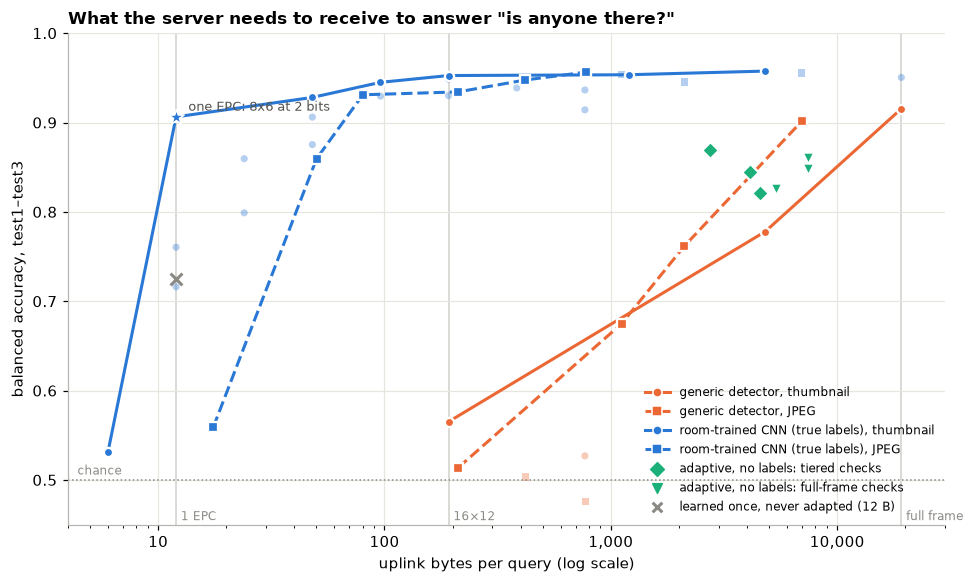

In [9]:
def frontier(d):
    # best accuracy reachable at or below each payload size (the Pareto front of one family)
    d = d.sort_values(['bytes', 'bal_acc']).groupby('bytes', as_index=False).last()
    return d[d.bal_acc >= d.bal_acc.cummax()]

fig, ax = plt.subplots(figsize=(9, 5.4))
handles = []
for d, color, label in [(gen, ORANGE, 'generic detector'), (sup, BLUE, 'room-trained CNN (true labels)')]:
    for fam, ls, mk in [('thumbnail', '-', 'o'), ('JPEG', '--', 's')]:
        f = d[d.family == fam]
        if len(f) == 0:
            continue
        ax.scatter(f.bytes, f.bal_acc, color=color, marker=mk, s=22, alpha=0.35, zorder=2, edgecolor='none')
        fr = frontier(f)
        ax.plot(fr.bytes, fr.bal_acc, ls, color=color, marker=mk, ms=6, zorder=3,
                markeredgecolor='white', markeredgewidth=1.5)
        handles.append(ax.plot([], [], ls, color=color, marker=mk, ms=6, markeredgecolor='white', label=f'{label}, {fam}')[0])
code12 = sup[sup.name == '8x6_b2_mean'].iloc[0]
ax.scatter([code12.bytes], [code12.bal_acc], s=110, marker='*', color=BLUE, zorder=4, edgecolor='white')
ax.annotate('one EPC: 8x6 at 2 bits', (code12.bytes, code12.bal_acc), xytext=(8, 4), textcoords='offset points', fontsize=8.5, color='#52514e')
for _, r in ada.iterrows():
    ax.scatter(r.bytes, r.bal_acc, s=60, marker='D' if r.check == 'tiered' else 'v', color=AQUA, zorder=4,
               edgecolor='white', linewidth=1.5)
handles += [ax.scatter([], [], marker='D', color=AQUA, s=40, label='adaptive, no labels: tiered checks'),
            ax.scatter([], [], marker='v', color=AQUA, s=40, label='adaptive, no labels: full-frame checks'),
            ax.scatter([], [], marker='x', color=GRAY, s=40, label='learned once, never adapted (12 B)')]
ax.legend(handles=handles, frameon=False, fontsize=8, loc='lower right')
ax.scatter([static['bytes']], [static['bal_acc']], s=60, marker='x', color=GRAY, zorder=4)
ax.axhline(0.5, color=GRAY, lw=1, ls=':')
ax.text(4.4, 0.506, 'chance', fontsize=8, color=GRAY)
logx(ax); ax.set_xlim(4, 30000); ax.set_ylim(0.45, 1.0)
ax.set_xlabel('uplink bytes per query (log scale)'); ax.set_ylabel('balanced accuracy, test1–test3')
ax.set_title('What the server needs to receive to answer "is anyone there?"', loc='left')
for b, lab in [(12, '1 EPC'), (192, '16×12'), (19200, 'full frame')]:
    ax.axvline(b, color='#d0cfca', lw=1, zorder=1); ax.text(b * 1.05, 0.455, lab, fontsize=8, color=GRAY)
plt.tight_layout(); plt.show()

In [5]:
cols = ['name', 'family', 'bytes', 'bal_acc', 'auc']
print('room-trained CNN'); display(sup[cols].sort_values('bytes'))
print('generic detector'); display(gen[cols + ['threshold']].sort_values('bytes'))
print('adaptive loop, no labels (detector teacher) and with true labels (oracle)')
display(pd.concat([ada, ada_or])[['learner', 'check', 'teacher', 'bytes', 'full_rate', 'bal_acc']].sort_values(['teacher', 'learner', 'check']))

room-trained CNN


,name,family,bytes,bal_acc,auc
24,8x6_b1_mean,thumbnail,6.000,0.531,0.723
20,4x3_b8_subsample,thumbnail,12.000,0.716,0.806
19,4x3_b8_mean,thumbnail,12.000,0.760,0.910
25,8x6_b2_mean,thumbnail,12.000,0.906,0.947
10,16x12_q5_jpeg,JPEG,17.526,0.559,0.803
4,16x12_b1_mean,thumbnail,24.000,0.799,0.882
26,8x6_b4_mean,thumbnail,24.000,0.860,0.949
5,16x12_b2_mean,thumbnail,48.000,0.906,0.949
27,8x6_b8_mean,thumbnail,48.000,0.928,0.944
28,8x6_b8_subsample,thumbnail,48.000,0.875,0.933


generic detector


,name,family,bytes,bal_acc,auc,threshold
1,16x12,thumbnail,192.000,0.565,0.474,0.033
7,jpeg32x24q50,JPEG,211.767,0.514,0.516,0.010
8,jpeg80x60q10,JPEG,419.327,0.503,0.409,0.135
2,32x24,thumbnail,768.000,0.527,0.548,0.010
5,jpeg160x120q5,JPEG,774.715,0.475,0.411,0.094
9,jpeg80x60q50,JPEG,1114.531,0.675,0.700,0.047
4,jpeg160x120q25,JPEG,2111.128,0.762,0.779,0.199
3,80x60,thumbnail,4800.000,0.778,0.814,0.184
6,jpeg160x120q90,JPEG,6990.217,0.902,0.942,0.326
0,160x120,thumbnail,19200.000,0.915,0.936,0.283


adaptive loop, no labels (detector teacher) and with true labels (oracle)


,learner,check,teacher,bytes,full_rate,bal_acc
0,batch_cells,full,detector,5339.749,0.277,0.825
1,batch_cells,tiered,detector,2738.199,0.136,0.870
2,online_cells,full,detector,7400.482,0.385,0.860
3,online_cells,tiered,detector,4569.236,0.233,0.821
4,online_pixels,full,detector,7450.743,0.387,0.849
5,online_pixels,tiered,detector,4118.890,0.209,0.844
0,batch_cells,full,oracle,8556.503,0.445,0.937
1,batch_cells,tiered,oracle,3455.435,0.173,0.908
2,online_cells,full,oracle,6043.414,0.314,0.921
3,online_cells,tiered,oracle,3243.832,0.165,0.931


**Reading the chart.** Left is cheaper, up is better. Each line is the best configuration of one family at or below each size (faint points are the others); solid lines are thumbnails, dashed lines JPEG.
* **Orange (generic detector)** climbs steadily with bytes and is at chance (balanced accuracy 0.48–0.57) everywhere below 1 KB. It needs 7 KB of JPEG or the full frame to reach 0.90.
* **Blue (decoder trained on this room)** is flat from 19,200 bytes down to about 100 and still at 0.91 at 12 bytes. The vertical gap between blue and orange at the same bytes is what knowledge of the room buys: at 192 bytes, 0.95 against 0.57.
* **Aqua (adaptive, no labels)** sits at 0.82–0.87 and 2.7–7.5 KB: better than the generic detector at the same bytes (it uses the room), worse than the supervised code by about 200× in bytes. Its bytes are almost all the full frames fetched for checking (section 1 of `tiered_checks.ipynb`).
* **The grey cross**, a code learned once and never updated, is cheap and wrong.

Two caveats on the comparison. The blue curve uses about 3,000 true labels from both layouts of the room, so it is an upper bound on what any decoder of that payload can do here, not a deployable method. And the aqua points use the first pass of the stream, scored on the `test1`–`test3` queries only, so each rests on about 380 queries.

## 2. JPEG against thumbnails at equal bytes

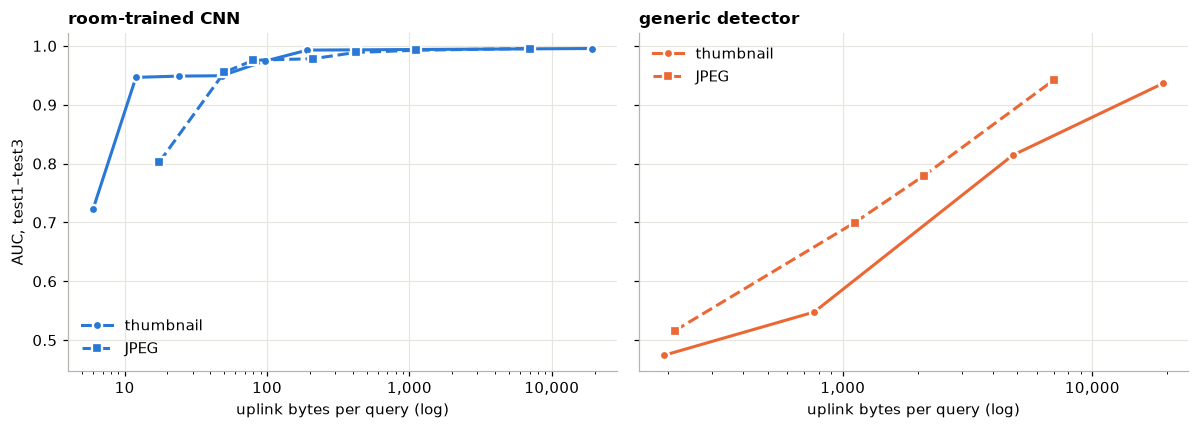

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, d, title in [(axs[0], sup, 'room-trained CNN'), (axs[1], gen, 'generic detector')]:
    for fam, ls, mk, color in [('thumbnail', '-', 'o', BLUE if d is sup else ORANGE), ('JPEG', '--', 's', BLUE if d is sup else ORANGE)]:
        f = d[d.family == fam].sort_values(['bytes', 'auc']).groupby('bytes', as_index=False).last()
        f = f[f.auc >= f.auc.cummax()]
        ax.plot(f.bytes, f.auc, ls, marker=mk, color=color, ms=6, markeredgecolor='white', markeredgewidth=1.5, label=fam)
    logx(ax); ax.set_title(title, loc='left'); ax.set_xlabel('uplink bytes per query (log)'); ax.legend(frameon=False)
axs[0].set_ylabel('AUC, test1–test3')
plt.tight_layout(); plt.show()

**JPEG against thumbnails.** AUC (threshold-free) for both decoders.
* **Room-trained decoder (left).** JPEG and thumbnails trace the same curve from about 80 bytes up (AUC 0.976–0.996). Below that the thumbnail family keeps going, to 0.947 at 12 bytes as 8×6 pixels at 2 bits, while the smallest JPEG (16×12 at quality 5, 17.5 bytes on average) falls to 0.80: at that size the JPEG bytes go to block structure and entropy-coding overhead rather than to the image. Even with the 328-byte header not counted, JPEG cannot fit one EPC.
* **Generic detector (right).** Here JPEG is better per byte: AUC 0.94 at 7 KB (160×120, quality 90) against 0.81 for the 4.8 KB 80×60 thumbnail, because the detector needs resolution more than precise gray levels. But below about 1 KB both are at or below chance.
* **Tag cost** (not in the chart): JPEG on the MSP430 adds an 8×8 DCT, quantisation and Huffman coding on top of the block mean; the ledger counts about 40 extra operations per output pixel, a rough estimate. A thumbnail or interval code needs none of that.

## 3. EPC loss

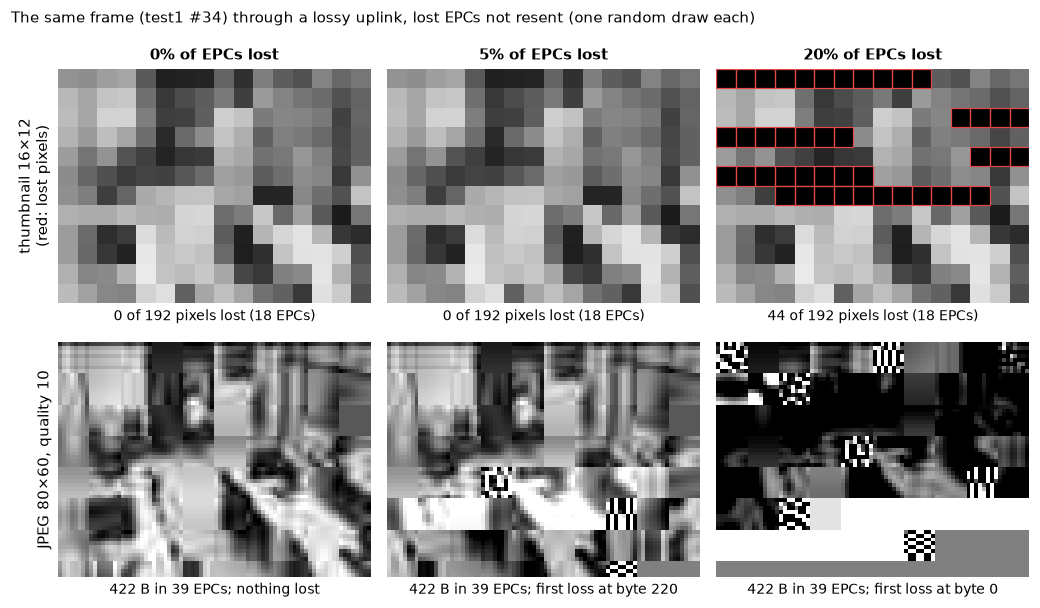

In [7]:
from semwisp.sim import Ledger
from semwisp import bits as B
x = frames['test1']['X'][34]
jt = JpegTag(80, 60, 10)
LOSS = [0.0, 0.05, 0.2]
fig, axs = plt.subplots(2, len(LOSS), figsize=(9.5, 5.6))
for c, p in enumerate(LOSS):
    # 16x12 thumbnail: a lost EPC blanks the pixels it carried
    payload = block_mean(x, 16, 12).ravel()
    rx = Link(p_loss=p, seed=3).uplink(payload, Ledger())
    img = np.where(rx.ok, rx.data, 0).reshape(12, 16)
    ax = axs[0, c]; tidy(ax)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest', extent=(0, 160, 120, 0))
    lost = (~rx.ok).reshape(12, 16)
    for yy, xx in zip(*np.nonzero(lost)):
        ax.add_patch(plt.Rectangle((xx * 10, yy * 10), 10, 10, fill=False, ec='#e34948', lw=0.8))
    k = Link().n_epcs(len(payload))[0]
    ax.set_xlabel(f'{int(lost.sum())} of 192 pixels lost ({k} EPCs)', fontsize=9)
    ax.set_title(f'{p:.0%} of EPCs lost', fontsize=10)
    # JPEG 80x60: a lost EPC breaks the entropy-coded scan from that point on
    scan = np.frombuffer(jt.encode(x), np.uint8)
    rx = Link(p_loss=p, seed=3).uplink(scan, Ledger())
    ax = axs[1, c]; tidy(ax)
    ax.imshow(jt.decode(rx.data), cmap='gray', vmin=0, vmax=255, interpolation='nearest', extent=(0, 160, 120, 0))
    per = Link().n_epcs(len(scan))
    first = np.flatnonzero(~rx.ok)
    ax.set_xlabel(f'{len(scan)} B in {per[0]} EPCs; ' + ('nothing lost' if not len(first) else
                  f'first loss at byte {first[0]}'), fontsize=9)
axs[0, 0].set_ylabel('thumbnail 16×12\n(red: lost pixels)', fontsize=9.5)
axs[1, 0].set_ylabel('JPEG 80×60, quality 10', fontsize=9.5)
fig.suptitle('The same frame (test1 #34) through a lossy uplink, lost EPCs not resent (one random draw each)',
             x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()


**What a lost EPC does** (one random draw per loss rate, the same frame as above). The thumbnail travels as 18 EPCs of 11 pixels each (one byte per EPC goes to the chunk index), so a lost EPC blanks a run of 11 pixels and the rest of the picture is untouched: at 20% loss this draw lost 4 of the 18 EPCs (44 pixels). JPEG's entropy-coded scan cannot be resynchronised after a gap, so everything after the first lost EPC is garbage: at 5% one lost EPC (at byte 220 of 422) wrecks the bottom of the image, and at 20% the first EPC was lost and nothing is left. The one-EPC code either arrives whole or not at all.

p_loss                              0.05    0.2  clean
family    name            bytes                       
JPEG      160x120_q5_jpeg 773.666  0.721  0.492  0.982
          32x24_q10_jpeg  80.240   0.946  0.819  0.976
          80x60_q10_jpeg  418.656  0.897  0.540  0.989
thumbnail 16x12_b8_mean   192.000  0.969  0.897  0.993
          32x24_b8_mean   768.000  0.971  0.876  0.992
          8x6_b2_mean     12.000   0.942  0.902  0.947

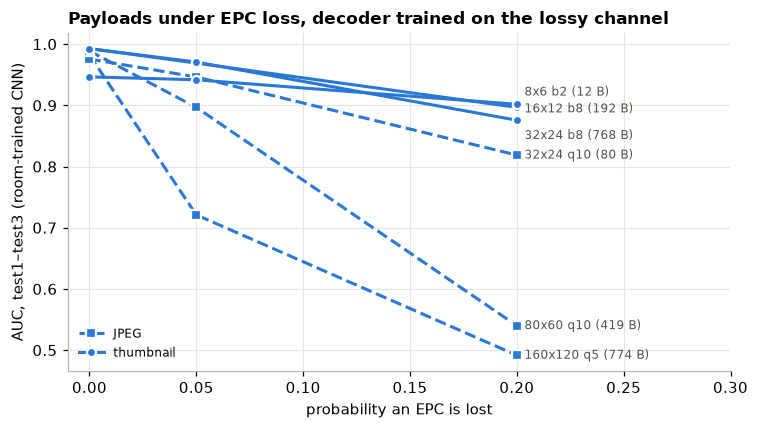

In [8]:
loss = R.channel_loss()
if len(loss):
    display(loss.pivot_table(index=['family', 'name', 'bytes'], columns='p_loss', values='auc').assign(
        clean=loss.groupby(['family', 'name', 'bytes']).auc_clean.first()))
    fig, ax = plt.subplots(figsize=(7, 4))
    for (fam, name), g in loss.groupby(['family', 'name']):
        g = pd.concat([pd.DataFrame([dict(p_loss=0.0, auc=g.auc_clean.iloc[0])]), g]).sort_values('p_loss')
        nb = loss[loss.name == name].bytes.iloc[0]
        ax.plot(g.p_loss, g.auc, '-' if fam == 'thumbnail' else '--', marker='o' if fam == 'thumbnail' else 's', color=BLUE, ms=6,
                markeredgecolor='white', markeredgewidth=1.5, label={'thumbnail': 'thumbnail', 'JPEG': 'JPEG'}[fam] if name in ('8x6_b2_mean', '32x24_q10_jpeg') else None)
        label = name.replace('_mean', '').replace('_jpeg', '').replace('_', ' ') + f' ({nb:,.0f} B)'
        ax.annotate(label, (g.p_loss.iloc[-1], g.auc.iloc[-1]), xytext=(5, {'8x6_b2_mean': 8, '16x12_b8_mean': -1, '32x24_b8_mean': -10}.get(name, 0)),
                    textcoords='offset points', fontsize=8, va='center', color='#52514e')
    ax.set_xlabel('probability an EPC is lost'); ax.set_ylabel('AUC, test1–test3 (room-trained CNN)')
    ax.set_title('Payloads under EPC loss, decoder trained on the lossy channel', loc='left')
    ax.legend(frameon=False, fontsize=8, loc='lower left'); ax.set_xlim(-0.01, 0.30); plt.tight_layout(); plt.show()

**EPC loss.** Each lost EPC (12 bytes) arrives as zeros and is not retransmitted; the decoder is trained on the same lossy channel, so it learns what a gap looks like.
* **Thumbnails degrade gracefully**: a lost EPC blanks a few pixels. At 20% loss, 16×12 keeps AUC 0.90 (0.99 clean) and 32×24 0.88.
* **JPEG collapses**: entropy-coded data cannot be resynchronised after a gap, so one lost EPC corrupts the rest of the image. 80×60 at quality 10 falls from 0.99 to 0.90 at 5% loss and to 0.54 at 20%; 160×120 at quality 5 falls to chance (0.49).
* **The one-EPC code is the most robust**: 0.947 clean, 0.942 at 5%, 0.902 at 20%. A query either arrives whole or not at all, and at 20% loss it is better than any of the larger payloads.

In a real Gen2 link a lost EPC fails its CRC and the reader can ask again, so loss turns into extra reads rather than errors: about k/(1−p) EPCs for a k-EPC payload, which is 1.25 reads for the one-EPC code at 20% loss and 88 for a 70-EPC thumbnail. Either way the cost grows with the payload. JPEG with restart markers would be more robust than shown here; that was not tested.

## Limits
* One room and its 760 test frames; one training seed per decoder; balanced accuracy at the decoder's own zero (no tuned threshold), so AUC is the better comparison between the blue curves.
* The adaptive points are first-pass, detector-taught, and scored on 380 queries each; `tiered_checks.ipynb` has the whole-stream numbers.
* Bytes, not energy: `semwisp/cost.py` has no measured constants, so the energy saving of one EPC over thousands is not quantified here, and neither is JPEG's computation on the tag.